In [1]:
import json
import os

from IPython.display import Image, Markdown, display


def load(name):
    with open(os.path.join("parts", name + ".json")) as file:
        return json.load(file)


def cell(value, form):
    if value is None:
        return "—"
    if callable(form):
        return form(value)
    return format(value, form) if form else str(value)


def table(rows, columns):
    """columns: (header, a key or a function of the row, a format spec or a function)"""
    def value(row, pick):
        return pick(row) if callable(pick) else row.get(pick)
    lines = ["| " + " | ".join(header for header, _, _ in columns) + " |",
             "|" + "---|" * len(columns)]
    for row in rows:
        lines.append("| " + " | ".join(cell(value(row, pick), form) for _, pick, form in columns) + " |")
    display(Markdown("\n".join(lines)))


def figure(path):
    display(Image(filename=path, width=720))

# EP4 measurement: NVIDIA GeForce RTX 5070 Laptop GPU

2026-11-22 17:08:40 · host `Welton` · engine code `72b86b63cbf7` ·
`python main.py measure --yes`

**What this is.** The raw results of one `measure` run: every engine run it made is a file in `points/`, every
analysis a file in `parts/`, every figure in `figures/`. The tables below are read from those files when the notebook
runs, so re-running it rebuilds them; the sentences that interpret them were written from the same numbers.

## The machine

| | |
|---|---|
| GPU | NVIDIA GeForce RTX 5070 Laptop GPU, compute capability 12.0, 36 SMs |
| per SM | 65536 registers, 1536 threads, 24 blocks |
| CPU (correctness only) | Intel(R) Core(TM) Ultra 7 255HX: the sequential engine the GPU's images are checked against; its speed is not compared |
| software | Build cuda_13.3.r13.3/compiler.38244171_0; driver 621.14 |

## What makes a valid run

A run measures speed only if the GPU is busy long enough and evenly enough. Two rules, the larger wins: (1) at least 1 s of photons, so that the launch and the clock's ramp-up don't dominate; (2) at least 32 chunks per resident thread, so that every SM gets a fair share and the slowest one doesn't decide the time (at 10⁷ photons on the laptop: 9 766 chunks for 27 648 threads, and pass times varied 0.6–1.6×; research/pass_order.py).

| binary | SMs | minimum N | by time (1 s) | by work (32 chunks per thread) | resident threads | N used here |
|---|---|---|---|---|---|---|
| gpu64 | 36 | 9.06e+08 | 6.40e+08 | 9.06e+08 | 27648 | 4.00e+09 |
| gpu64 | 1 | 2.52e+07 | 1.78e+07 | 2.52e+07 | 768 | 4.00e+09 |
| gpu32 | 36 | 1.10e+10 | 1.10e+10 | 1.06e+09 | 32256 | 6.00e+10 |
| gpu32 | 1 | 3.05e+08 | 3.05e+08 | 2.94e+07 | 896 | 6.00e+10 |

On one SM the work rule asks for far less (one SM's threads), and the same N simply runs longer. Two parts are below
the minimum **by design**: p(N) and the small-N strong sweep, whose point is to show what happens when the work is
too small. The validation checks use N = 10⁸, set by the statistics they need, not by speed.

## 1. Is the physics right? (validation)

**Question.** Does the GPU compute the same star as the sequential CPU engine, both photon by photon and in the
statistics of the image?

**Method.**
- *GPU vs CPU, the same photons:* the same seed, so the same random numbers; the images compared bit for bit.
- *GPU vs CPU, independent photons:* the same seed, so the same star and spots, but different chunks (each chunk is
  its own random stream): two independent Monte Carlo images of the same star. The χ² of their difference (frames
  summed), per degree of freedom: the same physics gives χ²/dof ≈ 1 (|σ| < 3 passes). Not different seeds: the seed
  also places the spots, so another seed is another star.
- *FP32 vs FP64:* the same seed, so the same photons; the fraction of photons that land in another pixel in FP32,
  next to the Poisson noise per lit pixel.

In [2]:
checks = load("validation")["checks"]
table(checks, [("check", lambda c: f"{c['name']} ({c['processor']}{c['precision']})", None),
               ("N", lambda c: c["data"].get("photons"), ".1e"),
               ("passed", "passed", lambda v: {True: "yes", False: "NO"}.get(v, "—")),
               ("result", "headline", None)])

| check | N | passed | result |
|---|---|---|---|
| independent (gpu64) | 1.0e+08 | yes | χ²/dof = 1.0035: the same physics within noise |
| precision (gpu64) | 4.0e+09 | — | FP32 moves 1.06e-04 of the photons (noise 1.94e-02); 17.51× the speed of FP64 |
| gpu (gpu64) | 1.0e+08 | yes | the GPU vs the sequential CPU: the images are identical, bit for bit |
| gpu (gpu32) | 1.0e+08 | — | the GPU vs the sequential CPU: 699 pixels differ (4.14e-05 of the photons moved) |

**What it means.**
- GPU vs the sequential CPU with independent photons: χ²/dof = 1.0035 over
  126225 pixels, +0.88 σ from 1:
  the same physics within the noise.
- FP32 moves 1.06e-04 of the photons to another pixel; the noise per lit pixel is
  1.94e-02, so the FP32 error is 184× smaller than the noise. FP32 is
  17.5× faster than FP64 on this GPU.
- GPU vs CPU, FP64: identical, bit for bit.
  FP32: 4.14e-05 of the photons moved (the GPU's `sinf`,
  `cosf` and fused multiply-adds round differently from the CPU's).

**Caveats.** The χ² test is statistical: about 1 run in 370 fails it by chance. The bit-for-bit results hold for this
build and this seed; they don't depend on N.

## 2. How fast is the GPU, one SM and all of them? (speed)

**Question.** Photons per second on one SM and on all 36, in FP64 and FP32. The unit of comparison is the SM:
the GPU against itself, not against another processor.

**Method.** The default star (200² pixels, 150 frames, 4 observers, one pass), the same N on one SM and on all of
them, repeated. The speed is N over the photon phase alone (the kernel): setup and save are left out. The one-SM run
is also the first point of the strong sweep (section 5).

| precision | SMs | N | photons/s (median) | min – max | SM clock (MHz) | power (W) | power cap | repeats |
|---|---|---|---|---|---|---|---|---|
| FP64 | 1 | 4.0e+09 | 1.81e+07 | 1.74e+07 – 1.81e+07 | 2887 | 30 | 0% | 3 |
| FP64 | 36 | 4.0e+09 | 6.36e+08 | 6.32e+08 – 6.4e+08 | 2880 | 58 | 0% | 3 |
| FP32 | 1 | 6.0e+10 | 3.22e+08 | 3.22e+08 – 3.22e+08 | 2895 | 35 | 0% | 3 |
| FP32 | 36 | 6.0e+10 | 1.06e+10 | 1.05e+10 – 1.06e+10 | 2624 | 115 | 93% | 3 |

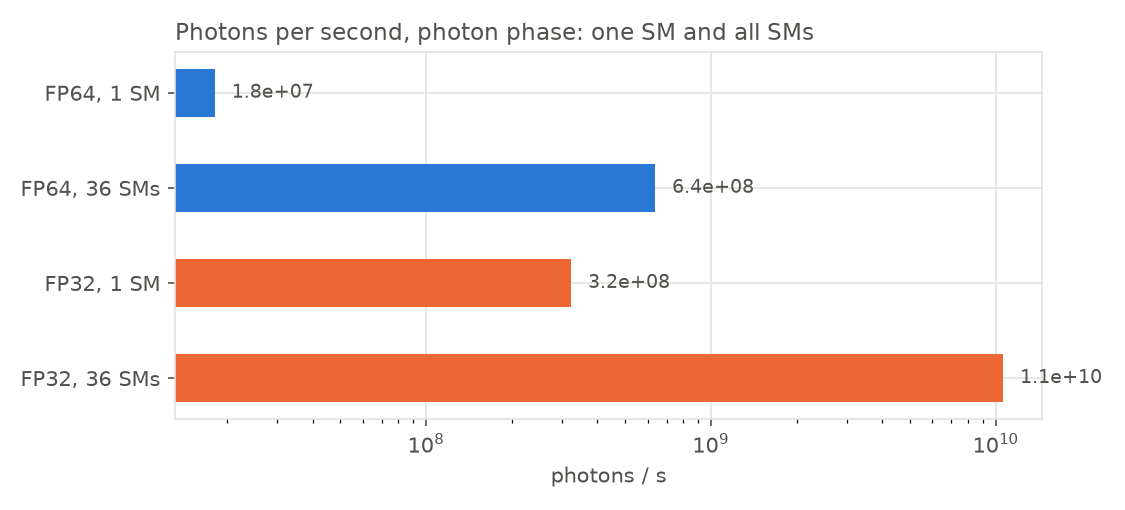

In [3]:
speed = load("speed")
table(speed["rows"], [("precision", lambda r: f"FP{r['precision']}", None), ("SMs", "sms", None), ("N", "photons", ".1e"),
                      ("photons/s (median)", lambda r: r["photons_per_second"]["median"], ".3g"),
                      ("min – max", lambda r: f"{r['photons_per_second']['min']:.3g} – {r['photons_per_second']['max']:.3g}", None),
                      ("SM clock (MHz)", "sm_clock_mhz", ".0f"), ("power (W)", "power_w", ".0f"),
                      ("power cap", "power_cap_share", ".0%"), ("repeats", lambda r: r["photons_per_second"]["repeats"], None)])
figure("figures/speed.png")

**What it means.**
- One SM: 1.81e+07 photons/s in FP64,
  3.22e+08 in FP32.
- All 36 SMs: 6.36e+08 in FP64 (35.2× one SM, so each
  SM keeps 98% of its one-SM speed), 1.06e+10 in FP32
  (32.9×, 91%).
- FP32 over FP64: 17.8× on one SM, 16.7× on all
  of them. This GPU has few FP64 units per SM, so an FP64 photon costs far more than an FP32 one.

**Caveats.** With every SM busy in FP32 the GPU reaches its power limit and lowers its clock, so the speed per SM falls
(the SM clock column); section 5 shows the same scaling in cycles, without the clock.

## 3. What the kernel is made of (kernel)

**Question.** What does the compiler make of `trace_photons`, and which changes to it matter?

**Method.** The resources come from the compiler (`ptxas -v`) and the CUDA runtime (`cudaFuncGetAttributes`, the
occupancy API). The instruction mix counts the instructions in the kernel's machine code (SASS) by the unit that runs
them. Each variant is a rebuild with one change, run at the same N as the baseline:
- `scene_in_global`: the scene in global memory instead of constant memory;
- `no_fma`: no fused multiply-adds (`--fmad=false`);
- `sections`: timers around each piece of the photon (cycles per section), to see where the time goes.

In [4]:
kernel = load("kernel")
print("Resources")
table([dict(r, precision=p) for p, r in kernel["resources"].items()],
      [("precision", "precision", None), ("registers", "registers", None), ("spills (B)", "spill_bytes", None),
       ("constant (B)", "constant_bytes", None), ("threads/block", "threads_per_block", None),
       ("blocks/SM", "blocks_per_sm", None), ("occupancy", "occupancy", ".2f")])
mix = kernel["instruction_mix"]
units = sorted({unit for counts in mix.values() for unit in counts})
print("Instruction mix (static: instructions in the code, not how often they run)")
table([dict({"unit": unit}, **{name: counts.get(unit, 0) for name, counts in mix.items()}) for unit in units],
      [("unit", "unit", None)] + [(name, name, None) for name in mix])
for precision, rows in kernel["variants"].items():
    print(f"Variants, {precision}")
    table(rows, [("variant", "variant", None), ("registers", "registers", None), ("spills (B)", "spill_bytes", None),
                 ("kernel (s)", lambda r: r["kernel_time"]["median"], ".3f"),
                 ("time vs baseline", "time_vs_baseline", ".3f"), ("cycles vs baseline", "cycles_vs_baseline", ".3f"),
                 ("same image", "image_equals_baseline", lambda v: "yes" if v else "no")])
for precision, sections in kernel["sections"].items():
    print(f"Where the time goes, {precision} (cycles per section, the sections build)")
    table(sorted(sections, key=lambda s: -s["share"]), [("section", "name", None), ("share", "share", ".1%")])

Resources


| precision | registers | spills (B) | constant (B) | threads/block | blocks/SM | occupancy |
|---|---|---|---|---|---|---|
| fp64 | 80 | 0 | 18048 | 768 | 1 | 0.50 |
| fp32 | 67 | 0 | 17256 | 896 | 1 | 0.58 |

Instruction mix (static: instructions in the code, not how often they run)


| unit | star_gpu64 | star_gpu32 |
|---|---|---|
| FP32 cores | 73 | 247 |
| FP64 units | 278 | 4 |
| atomics (L2) | 2 | 2 |
| constant loads | 46 | 49 |
| control flow | 1261 | 296 |
| conversions | 25 | 25 |
| global memory | 14 | 5 |
| integer units | 660 | 624 |
| local memory (stack, spills) | 5 | 20 |
| moves, special registers | 250 | 154 |
| other | 45 | 48 |
| special function unit (MUFU) | 13 | 12 |
| uniform datapath | 66 | 28 |
| warp-wide | 6 | 6 |

Variants, fp64


| variant | registers | spills (B) | kernel (s) | time vs baseline | cycles vs baseline | same image |
|---|---|---|---|---|---|---|
| baseline | 80 | 0 | 6.289 | 1.000 | 1.000 | yes |
| scene_in_global | 88 | 0 | 6.221 | 0.989 | 0.994 | yes |
| no_fma | 80 | 0 | 6.854 | 1.090 | 1.080 | yes |
| sections | 112 | 0 | 6.136 | 0.976 | 0.985 | yes |

... (2 outputs left out)

Where the time goes, fp64 (cycles per section, the sections build)


| section | share |
|---|---|
| direction | 33.4% |
| bin | 21.6% |
| surface | 20.2% |
| record | 15.0% |
| spots | 8.4% |
| pixel | 1.4% |
| chunk | 0.0% |

Where the time goes, fp32 (cycles per section, the sections build)


| section | share |
|---|---|
| direction | 40.8% |
| surface | 27.6% |
| record | 13.2% |
| spots | 9.2% |
| bin | 8.4% |
| pixel | 0.9% |
| chunk | 0.0% |

**What it means.**
- Registers: 80 (FP64) and 67 (FP32),
  spills 0 / 0 bytes; the launch
  gives occupancy 0.50 / 0.58
  (section 4 explains why).
- Constant vs global memory for the scene: no difference (0.99× the time in FP64, 1.03× in FP32). Every thread of a warp reads the same scene value at the same time, which the constant cache broadcasts, and L1 serves just as well.
- No FMA (separate multiply and add): 1.09× the time in FP64, 1.03× in FP32; the FP64 image is the same: fusing changed no photon's pixel here.
- The section timers cost 0.98× (FP64) and 1.10× (FP32): measuring changes what is measured. The largest section is *direction* (33% of the cycles, FP64) and *direction* (41%, FP32).

**Caveats.** The mix is static: a `NOP` or an FP64 instruction in a branch that never runs is counted like any other
(`research/nop_runs.py`, `research/fp64_in_fp32_kernel.py`). Times are medians of the repeats; their spread is in
`parts/kernel.json`.

## 4. Registers and occupancy (occupancy)

**Question.** The registers each thread needs limit how many warps an SM can hold (the occupancy). Would more warps
per SM make the kernel faster?

**The arithmetic.** An SM has 65536 registers and holds at most
1536 threads (48 warps of
32). Registers are given per warp, in steps of 8 per thread: a warp of threads needing *r* registers
takes ⌈r/8⌉·8·32. So the warps that fit are 65536 / (⌈r/8⌉·8·32), at most
48, and the occupancy is that over
48.

**Method.** Rebuild the kernel with `-maxrregcount` caps; the compiler then keeps fewer values in registers and spills
the rest to local memory. Each cap runs at the same N, the caps interleaved (forward, then backward) so that a clock
drifting during the sweep hits all of them alike. The speed is compared in **cycles of the slowest SM**, which don't
depend on the clock.

This GPU, uncapped


| precision | registers | per warp | warps the registers allow | of | threads per SM | occupancy at most |
|---|---|---|---|---|---|---|
| fp64 | 80 | 2560 | 25 | 48 | 800 | 0.52 |
| fp32 | 67 | 2304 | 28 | 48 | 896 | 0.58 |

The caps, fp64


| cap | registers | warps allowed | occupancy | spills (B) | cycles vs uncapped | time vs uncapped | MHz | power cap | same image |
|---|---|---|---|---|---|---|---|---|---|
| none | 80 | 25 | 0.50 | 0 | 1.000 | 1.000 | 2880 | 0% | yes |
| 72 | 72 | 28 | 0.58 | 0 | 0.992 | 0.986 | 2865 | 0% | yes |
| 64 | 64 | 32 | 0.67 | 24 | 0.996 | 0.987 | 2880 | 0% | yes |
| 56 | 56 | 36 | 0.75 | 84 | 1.044 | 1.031 | 2880 | 0% | yes |
| 48 | 48 | 42 | 0.83 | 164 | 1.064 | 1.052 | 2880 | 0% | yes |
| 40 | 40 | 51 | 1.00 | 344 | 1.089 | 1.078 | 2880 | 0% | yes |
| 32 | 32 | 64 | 1.00 | 444 | 1.091 | 1.087 | 2872 | 0% | yes |

The caps, fp32


| cap | registers | warps allowed | occupancy | spills (B) | cycles vs uncapped | time vs uncapped | MHz | power cap | same image |
|---|---|---|---|---|---|---|---|---|---|
| none | 67 | 28 | 0.58 | 0 | 1.000 | 1.000 | 2624 | 93% | yes |
| 64 | 55 | 36 | 0.75 | 0 | 1.011 | 1.034 | 2588 | 93% | yes |
| 56 | 52 | 36 | 0.75 | 0 | 1.030 | 1.047 | 2602 | 71% | yes |
| 48 | 48 | 42 | 0.83 | 24 | 1.035 | 1.048 | 2602 | 71% | yes |
| 40 | 40 | 51 | 1.00 | 80 | 1.036 | 1.054 | 2595 | 65% | yes |
| 32 | 32 | 64 | 1.00 | 156 | 1.048 | 1.097 | 2546 | 31% | yes |

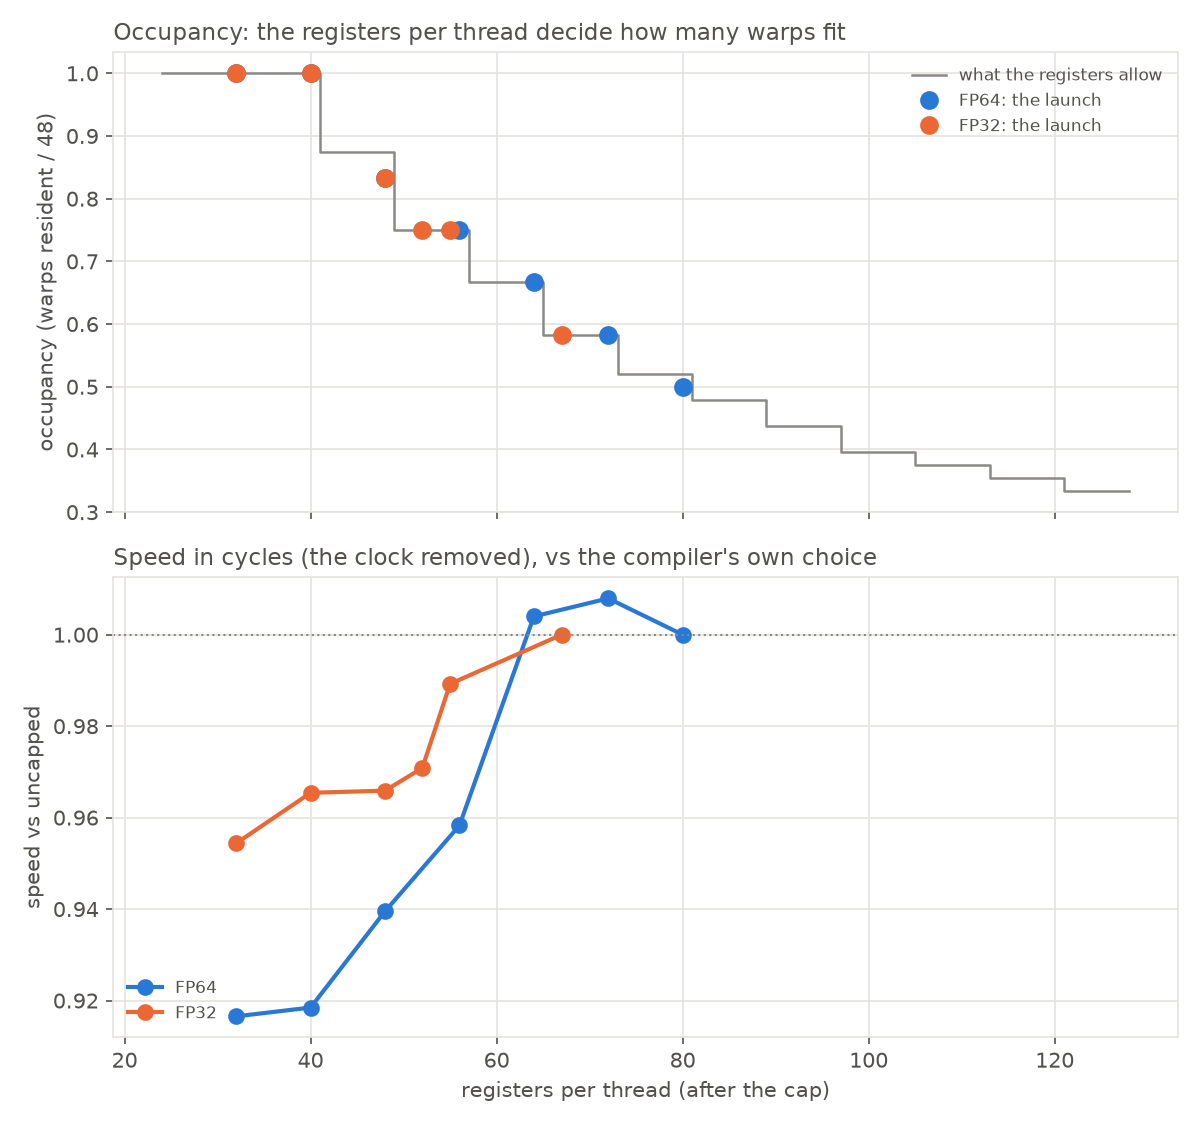

In [5]:
occupancy = load("occupancy")
print("This GPU, uncapped")
table([dict(r, precision=p) for p, r in occupancy["this_gpu"].items()],
      [("precision", "precision", None), ("registers", "registers", None), ("per warp", "registers_per_warp", None),
       ("warps the registers allow", "warps_allowed_by_registers", None), ("of", "max_warps", None),
       ("threads per SM", "threads_per_sm", None), ("occupancy at most", "occupancy_at_most", ".2f")])
for precision, rows in occupancy["rows"].items():
    print(f"The caps, {precision}")
    table(rows, [("cap", "cap", None), ("registers", "registers", None), ("warps allowed", "warps_allowed_by_registers", None),
                 ("occupancy", "occupancy", ".2f"), ("spills (B)", "spill_bytes", None),
                 ("cycles vs uncapped", "cycles_vs_baseline", ".3f"), ("time vs uncapped", "time_vs_baseline", ".3f"),
                 ("MHz", "sm_clock_mhz", ".0f"), ("power cap", "power_cap_share", ".0%"),
                 ("same image", "image_equals_baseline", lambda v: "yes" if v else "no")])
figure(occupancy["figure"])

**What it means.**
- FP64: the uncapped build uses 80 registers, so the registers allow occupancy 0.52; the launch gets 0.50, because blocks fit only whole. The fewest cycles: 72 registers (0.992× the uncapped cycles, occupancy 0.58). Full occupancy needs 40 registers: 1.089× the cycles, with 344 bytes spilled to local memory.
- FP32: the uncapped build uses 67 registers, so the registers allow occupancy 0.58. The fewest cycles: 67 registers (1.000× the uncapped cycles, occupancy 0.58). Full occupancy needs 40 registers: 1.036× the cycles, with 80 bytes spilled to local memory.

Other GPUs, from the compiler alone:
- A30 (NVIDIA's Ampere tuning guide) (sm_80): FP64 96 registers → occupancy at most 0.33; FP32 76 → 0.39 (compiled here, not run).

**Caveats.** "Power cap" is the share of `nvidia-smi` samples in which the driver held the clock down for power; the
cycles are immune to it, the times are not. On a GPU where the kernel waits on memory or on long latencies, more warps
can hide that wait; where it is bound by its arithmetic units, they can't.

## 5. Scaling: Amdahl and Gustafson (scaling)

**Question.** How does the time change with the number of SMs, for a fixed problem (strong scaling, Amdahl) and for a
problem that grows with the SMs (weak scaling, Gustafson)?

**Method.** The engine's `--sms n` keeps the work on n SMs. Strong: the same N on every n. Weak: N proportional to n.
Each point is repeated, interleaved; medians are used. Two times are kept: the **photon phase** (the kernel) and the
**whole run** (with the setup, zeroing and saving, which don't get faster with more SMs). Amdahl's law
T(n) = T(1)·(s + p/n) is fitted by least squares; Gustafson's scaled speedup is n − s′(n − 1).

### 5.1 Strong scaling

| SMs | photon phase (s) | whole run (s) | speedup, photons | speedup, whole run | speedup, cycles | SM clock (MHz) |
|---|---|---|---|---|---|---|
| 1 | 221.313 | 221.582 | 1.00 | 1.00 | 1.00 | 2887 |
| 2 | 110.561 | 110.831 | 2.00 | 2.00 | 2.00 | 2887 |
| 3 | 73.709 | 73.971 | 3.00 | 3.00 | 3.00 | 2887 |
| 4 | 55.283 | 55.558 | 4.00 | 3.99 | 4.00 | 2887 |
| 6 | 36.867 | 37.142 | 6.00 | 5.97 | 6.00 | 2887 |
| 9 | 24.578 | 24.843 | 9.00 | 8.92 | 9.00 | 2887 |
| 12 | 18.439 | 18.687 | 12.00 | 11.86 | 12.00 | 2887 |
| 18 | 12.299 | 12.574 | 17.99 | 17.62 | 17.99 | 2887 |
| 24 | 9.227 | 9.497 | 23.98 | 23.33 | 23.99 | 2887 |
| 36 | 6.290 | 6.573 | 35.18 | 33.71 | 35.69 | 2880 |

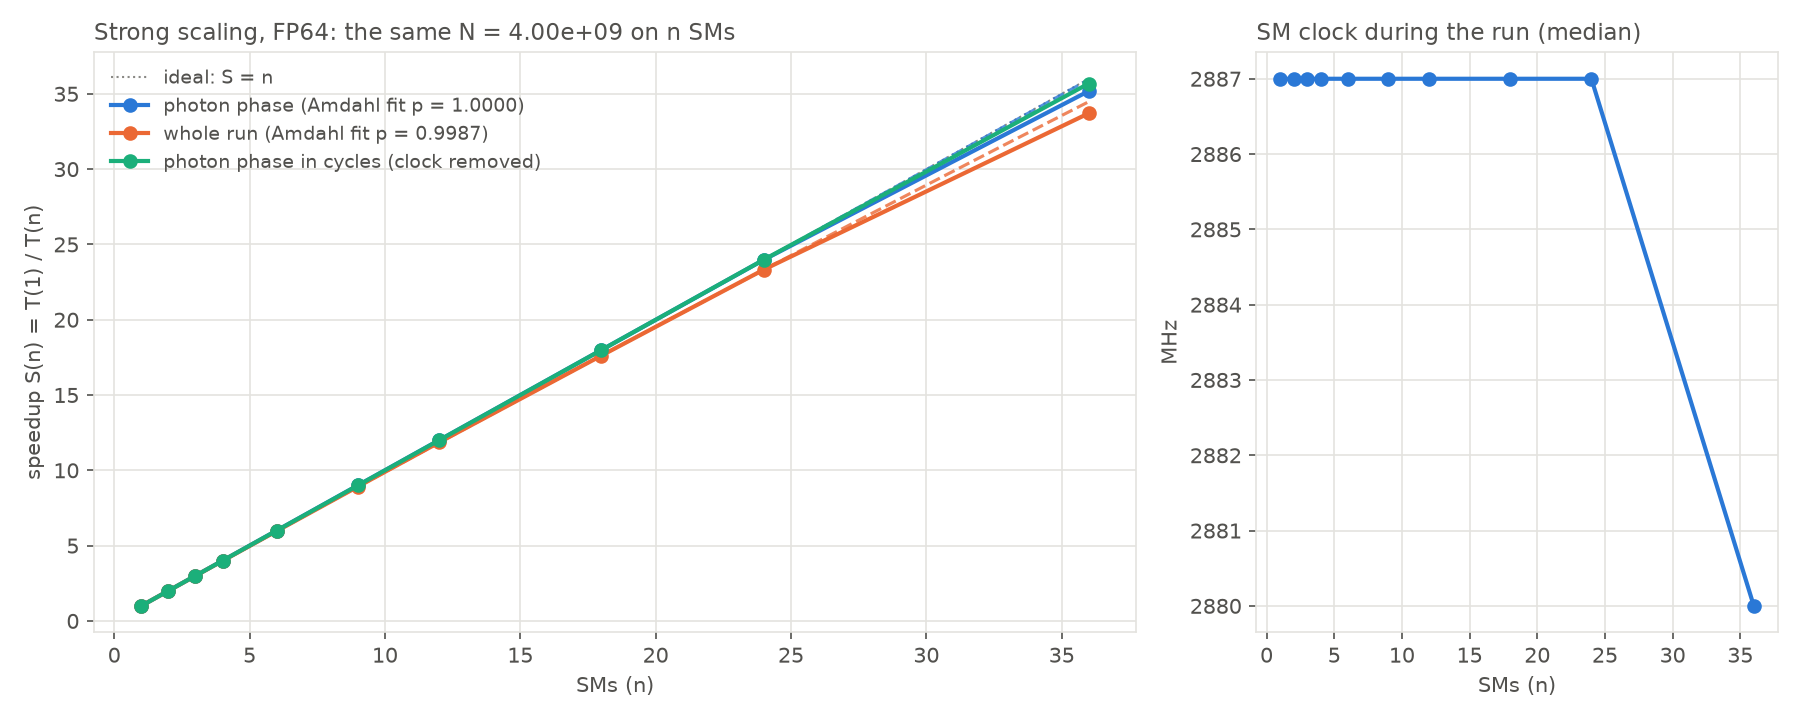

In [6]:
strong = load("scaling")["strong-fp64"]
table([{"sms": n, "photons": strong["photon_time"][str(n)], "whole": strong["whole_run_time"][str(n)],
         "s_photons": strong["speedup_photon_phase"][str(n)], "s_whole": strong["speedup_whole_run"][str(n)],
         "s_cycles": strong["speedup_cycles"].get(str(n)), "mhz": strong["sm_clock_mhz"].get(str(n))}
       for n in strong["sms"]],
      [("SMs", "sms", None), ("photon phase (s)", "photons", ".3f"), ("whole run (s)", "whole", ".3f"),
       ("speedup, photons", "s_photons", ".2f"), ("speedup, whole run", "s_whole", ".2f"),
       ("speedup, cycles", "s_cycles", ".2f"), ("SM clock (MHz)", "mhz", ".0f")])

figure("figures/strong_fp64.png")

| SMs | photon phase (s) | whole run (s) | speedup, photons | speedup, whole run | speedup, cycles | SM clock (MHz) |
|---|---|---|---|---|---|---|
| 1 | 186.163 | 186.436 | 1.00 | 1.00 | 1.00 | 2895 |
| 2 | 93.150 | 93.418 | 2.00 | 2.00 | 2.00 | 2895 |
| 3 | 62.096 | 62.358 | 3.00 | 2.99 | 3.00 | 2895 |
| 4 | 46.600 | 46.862 | 3.99 | 3.98 | 4.00 | 2895 |
| 6 | 31.091 | 31.347 | 5.99 | 5.95 | 6.00 | 2895 |
| 9 | 20.786 | 21.044 | 8.96 | 8.86 | 8.99 | 2880 |
| 12 | 15.588 | 15.844 | 11.94 | 11.77 | 12.00 | 2880 |
| 18 | 10.402 | 10.663 | 17.90 | 17.48 | 17.99 | 2880 |
| 24 | 7.857 | 8.121 | 23.69 | 22.96 | 23.98 | 2857 |
| 36 | 5.656 | 5.939 | 32.91 | 31.39 | 35.92 | 2624 |

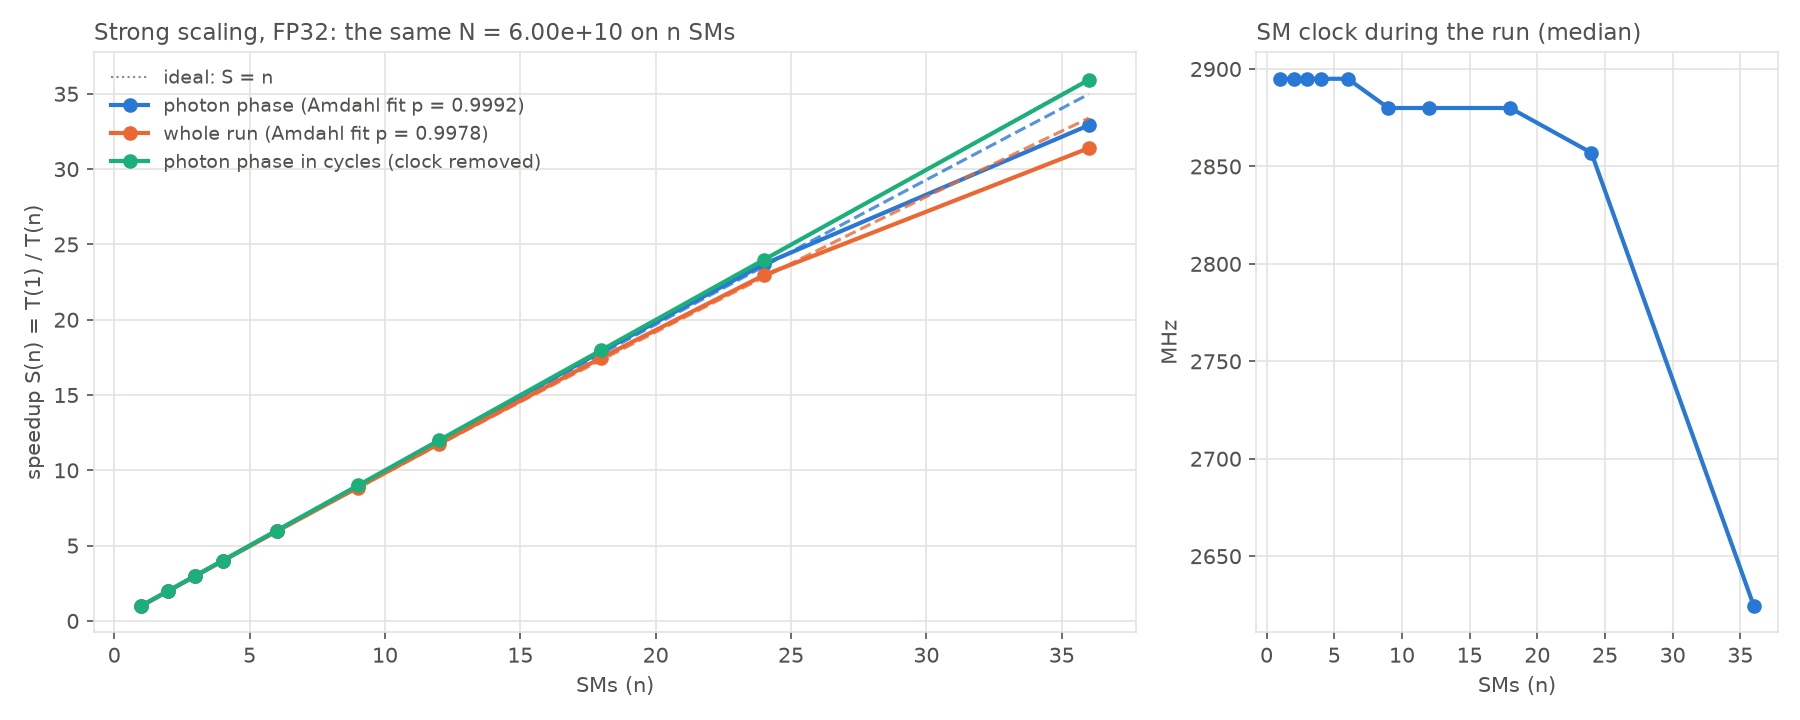

In [7]:
strong = load("scaling")["strong-fp32"]
table([{"sms": n, "photons": strong["photon_time"][str(n)], "whole": strong["whole_run_time"][str(n)],
         "s_photons": strong["speedup_photon_phase"][str(n)], "s_whole": strong["speedup_whole_run"][str(n)],
         "s_cycles": strong["speedup_cycles"].get(str(n)), "mhz": strong["sm_clock_mhz"].get(str(n))}
       for n in strong["sms"]],
      [("SMs", "sms", None), ("photon phase (s)", "photons", ".3f"), ("whole run (s)", "whole", ".3f"),
       ("speedup, photons", "s_photons", ".2f"), ("speedup, whole run", "s_whole", ".2f"),
       ("speedup, cycles", "s_cycles", ".2f"), ("SM clock (MHz)", "mhz", ".0f")])

figure("figures/strong_fp32.png")

**What it means.**
- FP64, N = 4.00e+09: 35.2× on 36 SMs for the photon phase (Amdahl p = 1.0000), 33.7× for the whole run (p = 0.9987, ceiling 1/s = 793); in cycles 35.7×, so the difference from the seconds is the clock. The serial share measured from the phases: 0.0012 (fitted: 0.0013).
- FP32, N = 6.00e+10: 32.9× on 36 SMs for the photon phase (Amdahl p = 0.9992), 31.4× for the whole run (p = 0.9978, ceiling 1/s = 447); in cycles 35.9×, so the difference from the seconds is the clock. The serial share measured from the phases: 0.0014 (fitted: 0.0022).

### 5.2 Weak scaling

FP64


| SMs | N | photon phase (s) | whole run (s) | scaled speedup | efficiency |
|---|---|---|---|---|---|
| 1 | 1.11e+08 | 6.143 | 6.404 | 1.00 | 1.000 |
| 2 | 2.22e+08 | 6.144 | 6.436 | 1.95 | 1.000 |
| 3 | 3.33e+08 | 6.144 | 6.412 | 2.91 | 1.000 |
| 4 | 4.44e+08 | 6.145 | 6.426 | 3.86 | 1.000 |
| 6 | 6.67e+08 | 6.148 | 6.429 | 5.77 | 0.999 |
| 9 | 1.00e+09 | 6.150 | 6.412 | 8.66 | 0.999 |
| 12 | 1.33e+09 | 6.150 | 6.424 | 11.52 | 0.999 |
| 18 | 2.00e+09 | 6.152 | 6.403 | 17.31 | 0.999 |
| 24 | 2.67e+09 | 6.154 | 6.410 | 23.04 | 0.998 |
| 36 | 4.00e+09 | 6.290 | 6.573 | 33.68 | 0.977 |

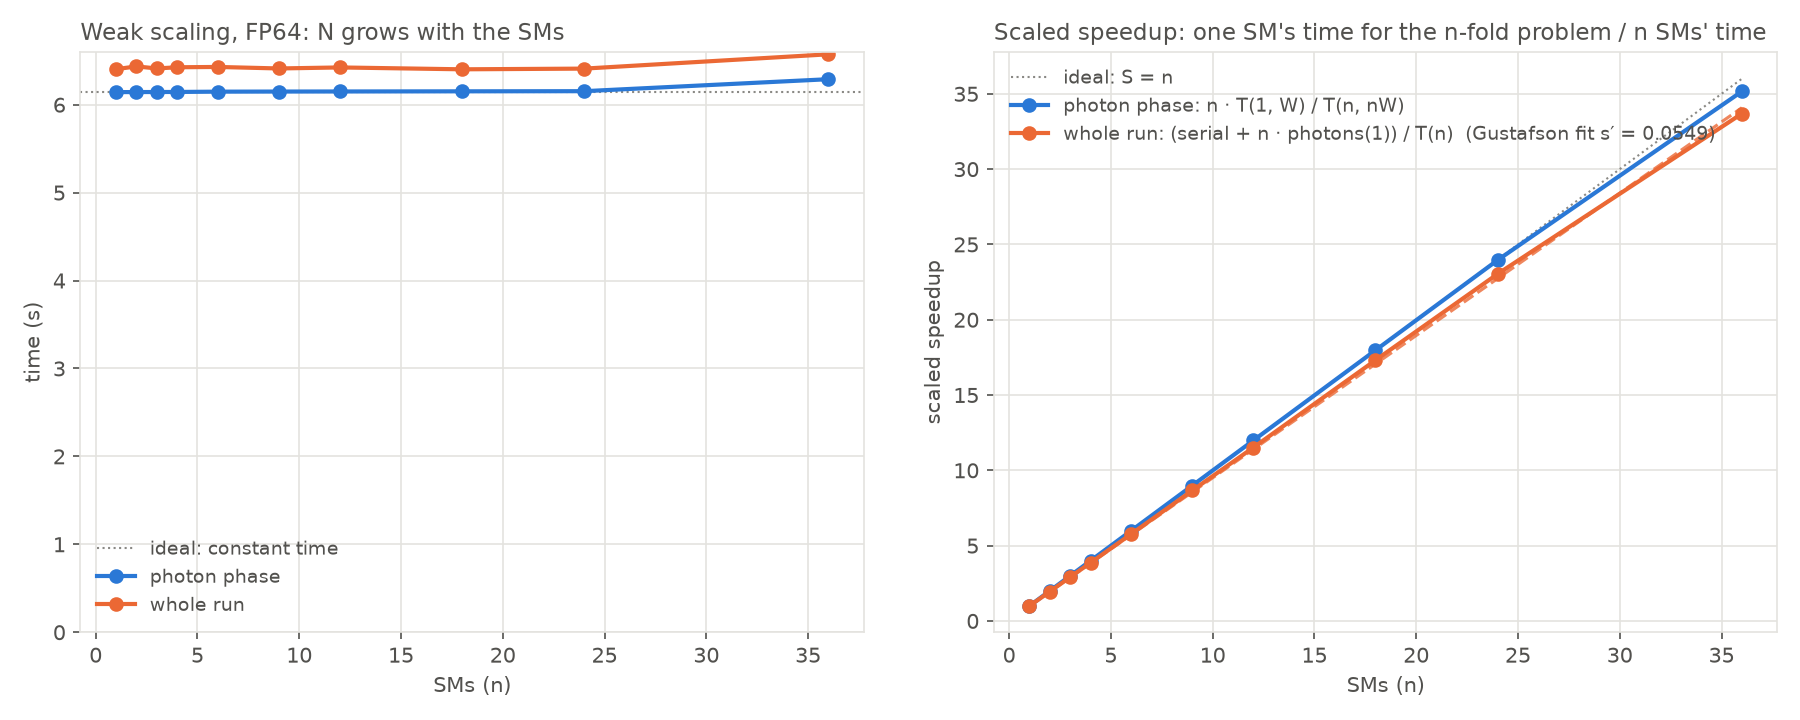

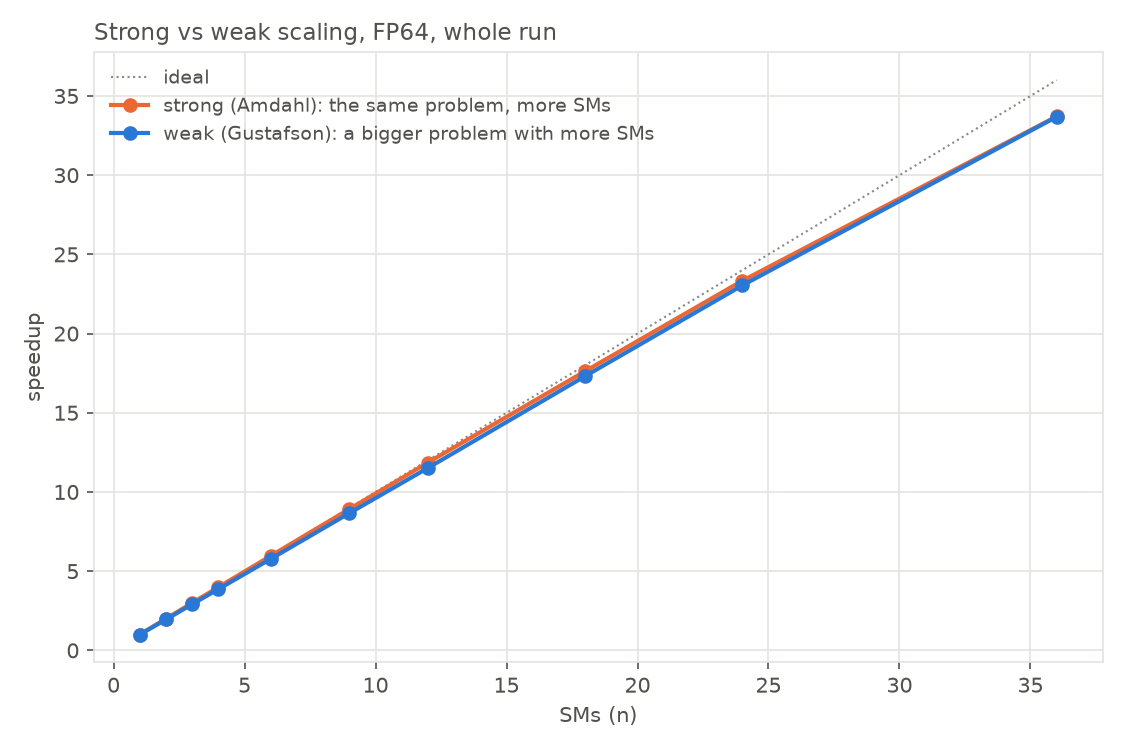

FP32


| SMs | N | photon phase (s) | whole run (s) | scaled speedup | efficiency |
|---|---|---|---|---|---|
| 1 | 1.67e+09 | 5.173 | 5.434 | 1.00 | 1.000 |
| 2 | 3.33e+09 | 5.175 | 5.449 | 1.95 | 0.999 |
| 3 | 5.00e+09 | 5.176 | 5.446 | 2.90 | 0.999 |
| 4 | 6.67e+09 | 5.179 | 5.446 | 3.85 | 0.999 |
| 6 | 1.00e+10 | 5.183 | 5.479 | 5.71 | 0.998 |
| 9 | 1.50e+10 | 5.196 | 5.462 | 8.57 | 0.995 |
| 12 | 2.00e+10 | 5.197 | 5.468 | 11.40 | 0.995 |
| 18 | 3.00e+10 | 5.202 | 5.477 | 17.05 | 0.994 |
| 24 | 4.00e+10 | 5.265 | 5.531 | 22.49 | 0.982 |
| 36 | 6.00e+10 | 5.656 | 5.939 | 31.40 | 0.915 |

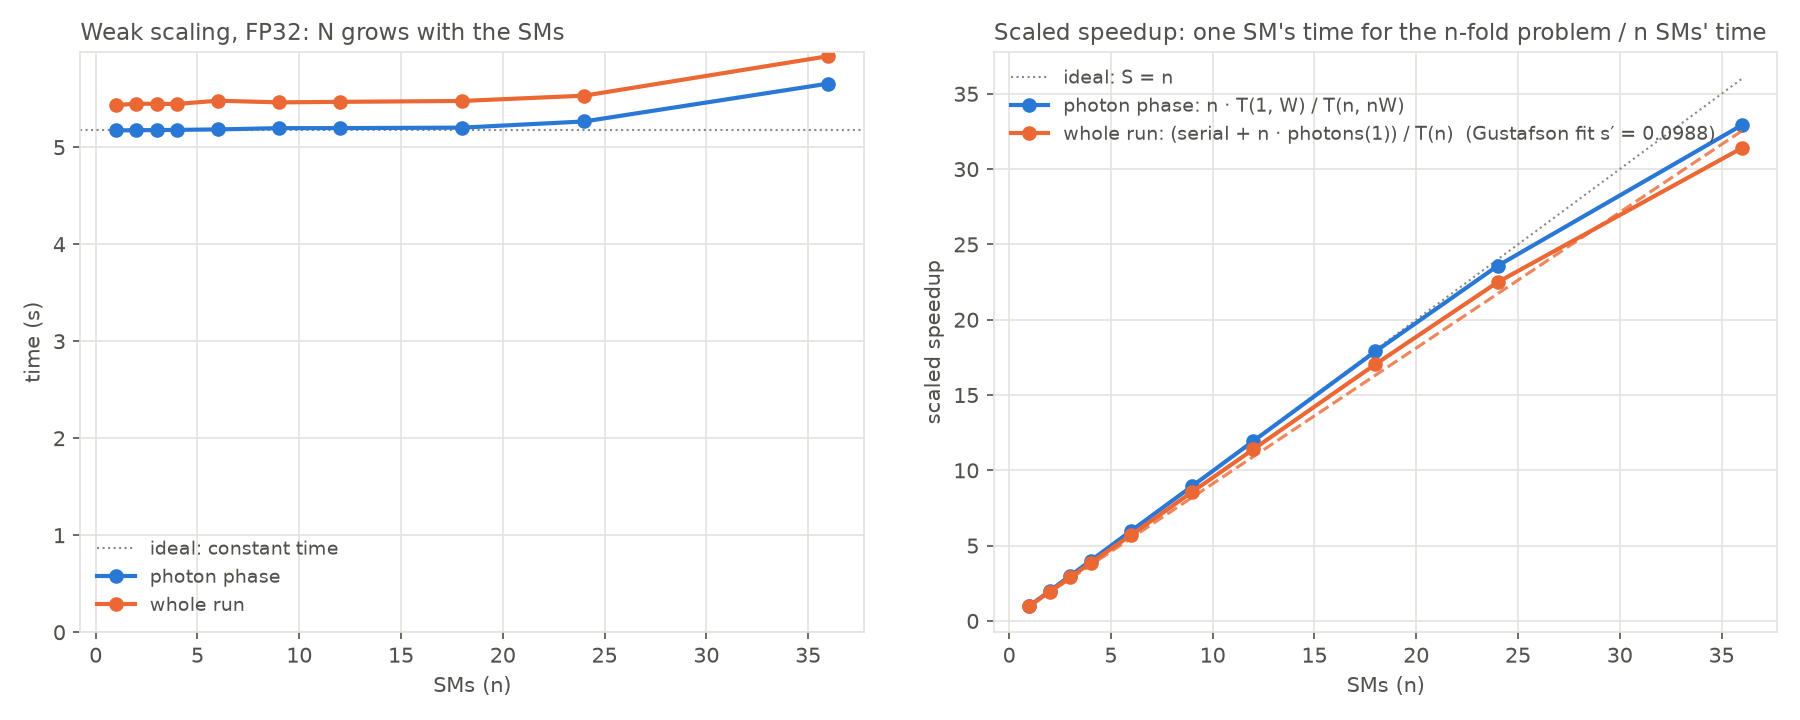

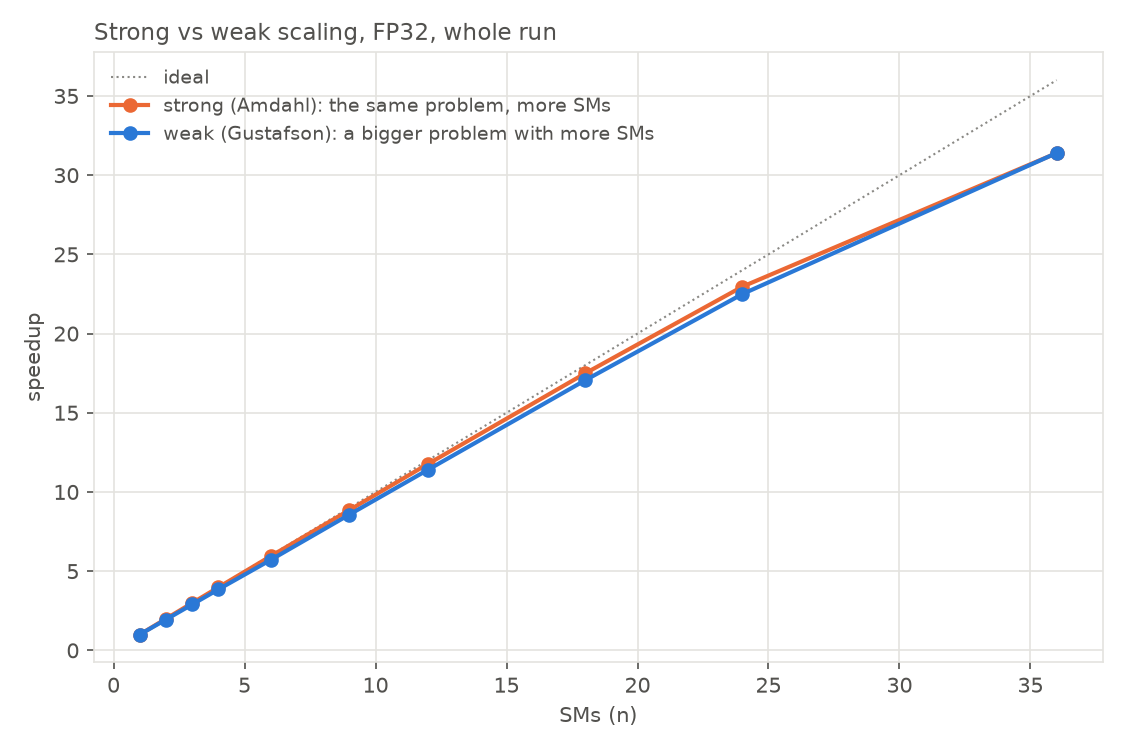

In [8]:
for precision in (64, 32):
    weak = load("scaling")[f"weak-fp{precision}"]
    print(f"FP{precision}")
    table([{"sms": n, "photons": weak["photons"][str(n)], "time": weak["photon_time"][str(n)],
            "whole": weak["whole_run_time"][str(n)], "scaled": weak["scaled_speedup_whole_run"][str(n)],
            "efficiency": weak["efficiency_photon_phase"][str(n)]} for n in weak["sms"]],
          [("SMs", "sms", None), ("N", "photons", ".2e"), ("photon phase (s)", "time", ".3f"),
           ("whole run (s)", "whole", ".3f"), ("scaled speedup", "scaled", ".2f"), ("efficiency", "efficiency", ".3f")])
    figure(f"figures/weak_fp{precision}.png")
    figure(f"figures/strong_vs_weak_fp{precision}.png")

**What it means.**
- FP64: on 36 SMs the efficiency is 0.977; Gustafson's serial share fitted s′ = 0.0549, measured 0.0406.
- FP32: on 36 SMs the efficiency is 0.915; Gustafson's serial share fitted s′ = 0.0988, measured 0.0476.

### 5.3 When the work is small: Amdahl's ceiling (below the minimum by design)

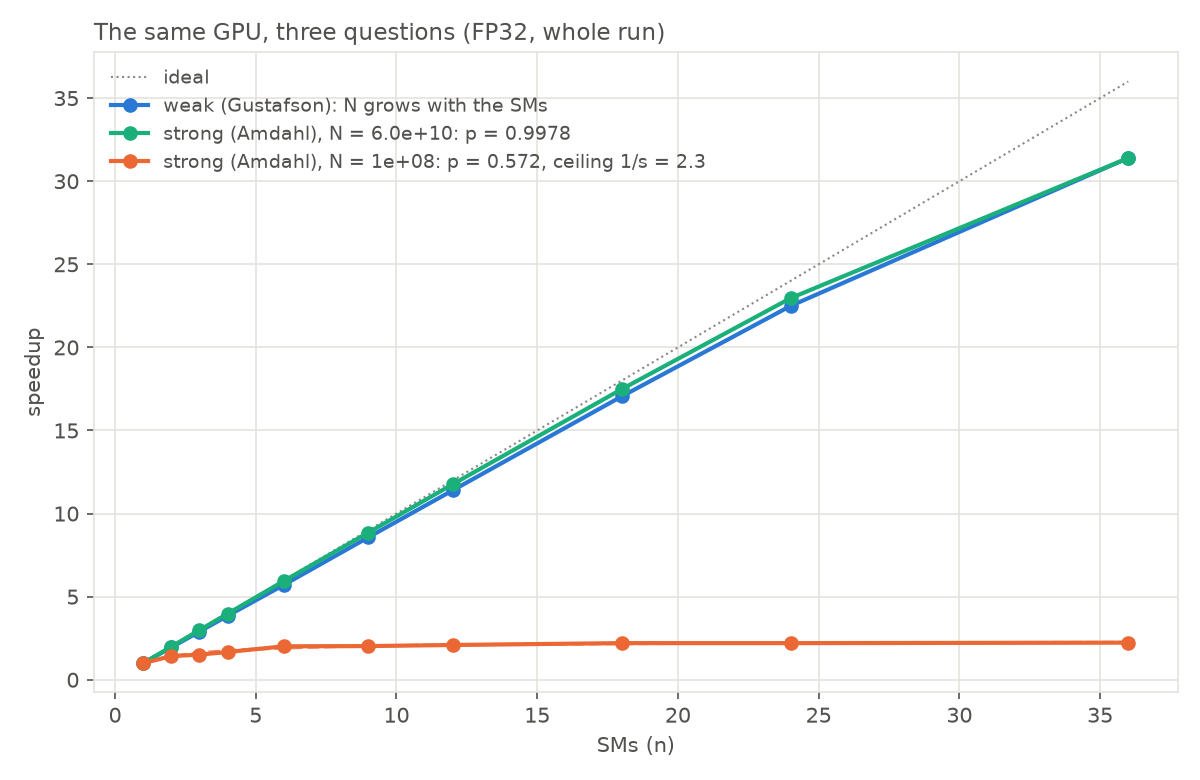

In [9]:
figure("figures/amdahl_ceiling_fp32.png")

**What it means.** At N = 1e+08 (FP32) the whole run on 36 SMs is only
2.2× faster than on one: the serial part (setup, zeroing, saving) is now a large
share, and Amdahl's fit gives p = 0.572, a ceiling of
2.3× however many SMs are added. The same GPU scales almost perfectly when the
problem is large (5.1) or grows with it (5.2).

### 5.4 p(N): the parallel fraction grows with the problem (below the minimum by design)

| N | p, photon phase | p, whole run |
|---|---|---|
| 1e+05 | 0.00553 | -0.02309 |
| 1e+06 | 0.56408 | 0.04346 |
| 1e+07 | 0.94317 | 0.17739 |
| 1e+08 | 0.99302 | 0.56826 |
| 1e+09 | 0.99935 | 0.92178 |
| 1e+10 | 0.99840 | 0.98956 |

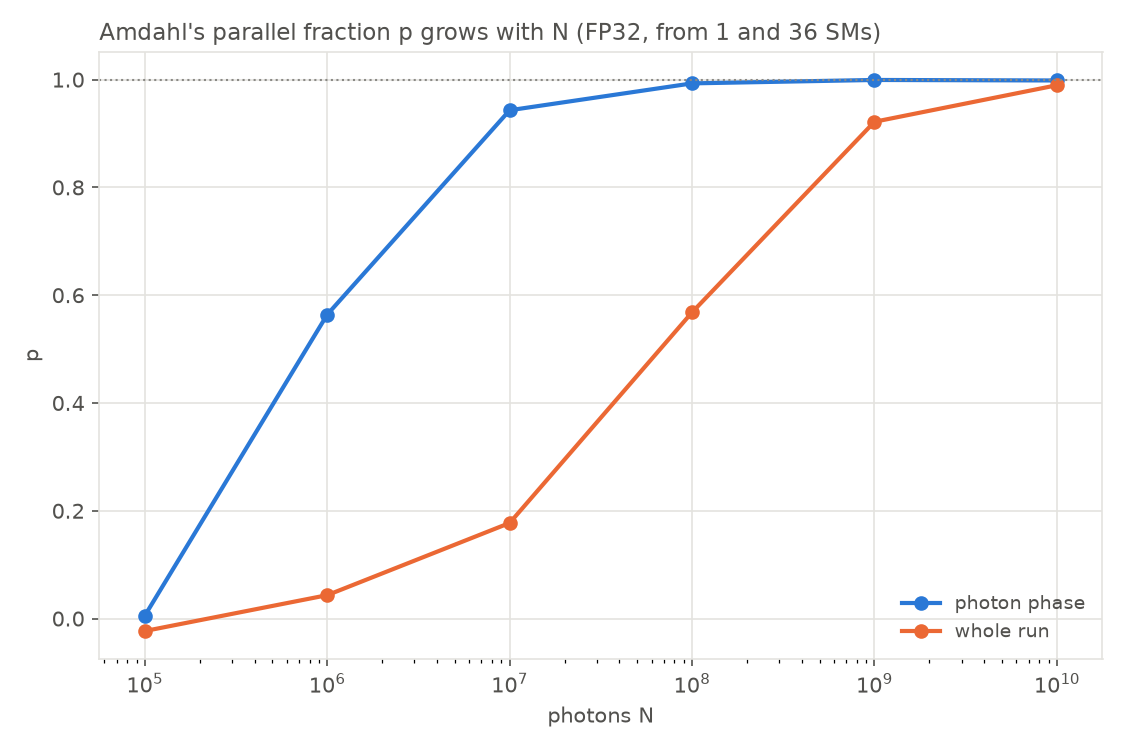

In [10]:
size = load("scaling")["problem-size-fp32"]
table([{"n": int(n), "p_photons": size["p_photon_phase"][str(n)], "p_whole": size["p_whole_run"][str(n)]}
       for n in size["sizes"]], [("N", "n", ".0e"), ("p, photon phase", "p_photons", ".5f"), ("p, whole run", "p_whole", ".5f")])
figure("figures/problem_size.png")

**What it means.** Amdahl's p is not a property of the program alone: from N = 1e+05 to
1e+10 it goes from 0.006 to 0.99840
for the photon phase, and from -0.023 to 0.9896 for the
whole run. The work grows with N; the serial part doesn't.

**Caveats.** On many SMs in FP32 the clock falls under the power cap, so seconds understate the scaling; the cycles
don't (the "speedup, cycles" column). Points below the minimum N are kept on purpose and labelled.

## Appendix: the data

**The folder.**
- `run.json`: what was asked (the options, the reference N per binary), the machine, the status.
- `machine.json`: the GPU's limits, the software, the environment checks, the minimum N.
- `plan.json`: every planned run with its prediction (seconds, memory, passes) and its validity.
- `points/<run>.json`: one file per engine run (the name says the binary, the variant, the SMs, N and the repeat).
- `parts/<part>.json`: the analyses, which these tables read:
- `parts/validation.json`
- `parts/speed.json`
- `parts/kernel.json`
- `parts/occupancy.json`
- `parts/scaling.json`
- `figures/`: the figures, each with a `.json` of the numbers it plots.
- `progress.log`: each run's measured vs predicted time.

**The fields of a point.**

| field | meaning |
|---|---|
| `processor, precision, sms, photons, variant, repeat, star` | what was asked (sms empty = all SMs) |
| `SUMMARY.PHOTONS_TIME` | seconds of the photon phase (the kernel, or the CPU loop): the speed is measured on it |
| `SUMMARY.TIME` | seconds of the whole engine run: setup + zero + photons + copy + save |
| `SUMMARY.SETUP_TIME, ZERO_TIME, COPY_TIME, SAVE_TIME` | the serial parts of the run |
| `SUMMARY.PHOTONS_PER_SECOND` | N / PHOTONS_TIME |
| `SUMMARY.RECORDED, BLOCKED, MISSED` | photons that reached an observer's image, hit a spot, or no observer's μ bin |
| `SUMMARY.REGISTERS_PER_THREAD, LOCAL_BYTES_PER_THREAD` | the kernel's registers, and its local memory (spills) |
| `SUMMARY.THREADS_PER_BLOCK, BLOCKS_PER_UNIT, OCCUPANCY` | the launch chosen by the occupancy API |
| `KERNEL[].KERNEL_TIME` | seconds of each pass's kernel, from CUDA events |
| `SMS[].CYCLES` | clock cycles of the slowest SM in each pass: speed with the clock removed |
| `GPU_MONITOR.*` | nvidia-smi sampled every 200 ms: clock (MHz), power (W), temperature, and the share of samples with each clock-limit reason active (POWER_CAP, VOLTAGE_CEILING, ...) |
| `IMAGE_DIGEST` | a hash of the observers' images: equal digests = identical images, bit for bit |
| `PROCESS_TIME` | wall-clock seconds of the engine process, measured from Python |
| `validity` | valid, below the minimum by design (p(N), small N), or INVALID |